# Where the model picks its coding algorithm: targeted plan-subspace pushes in Qwen3-8B (C2c demo)

**Artifact:** experiment `art_SHaWv77P1XCI` (iteration 4) · **Model:** `Qwen/Qwen3-8B` at a pinned revision (`b968826d…`), FP8 W8A8 on a 16 GB RTX 2000 Ada, thinking off, temperature 1.

Asked to solve a standard coding task, Qwen3-8B writes the *same* algorithm almost every time: union-find for "count the connected components", a full sort for "return the k-th smallest value", Dijkstra for weighted shortest paths. Iteration 3 found that random pushes on the hidden states of the task-specification tokens sometimes make the model write a *different, correct* algorithm. This experiment asks **where that choice lives**: is there a *plan subspace* `P_t` in the residual stream that explains which pushes move the algorithm?

`P_t` is defined per task t and decoder block l = 12–35. It is spanned by the centroid differences `c_X − c_default` of the task-spec states (the mean over the `Task: …` tokens) when the prompt *forces* algorithm X ("Implement X", 30 paraphrases per algorithm). A name-masked twin is built from descriptions only. All 4,144 prompts were used, and every predictor was sha256-committed before any sampling. Scale: 13,500 CRN-coupled programs, labelled by a runtime tracer + AST with a blind LLM judge only on disagreement; 2.51 GPU-hours.

### What this notebook runs
The full pipeline (`method.py`) needs the 16 GB model on a GPU. This notebook replays the **CPU analysis of claim C2c** from the pipeline's `analyze` stage on the labelled programs the GPU stage produced, and recomputes the published numbers. The code is copied from `analysis/c2c.py`, `analysis/common.py` and `analysis/run_all.py → c2c()`; only the data access changes.

> **C2c:** does a *targeted* push along the default → runner-up centroid axis, at the predicted half-distance, beat a *random* push of the same per-position magnitude?

The demo data (`mini_demo_data.json`, 100 examples) holds every CRN slot of the C2c arms for two tasks:
- **T10**: connected components; default `union_find`, runner-up `dfs`.
- **T03**: k-th smallest; default `full_sort`, runner-up `quickselect`.

### Headline results of the full run (for orientation)
| Claim | Outcome |
|---|---|
| Plan-subspace reliability | split-half principal cosine 0.89–0.97 (random subspaces: 0.02) |
| **C2a** (primary): the projection share π(u) ranks which of 40 fresh random pushes move the algorithm | **DISCONFIRMED**: ρ < 0.2 on 6/6 movable tasks; pooled within-task ρ = 0.03 [−0.03, 0.09] |
| Decomposition (20 confirmed escaping pushes) | removing the push's `P_t` component keeps the effect (median R = 1.00), so `P_t` is not needed |
| **C2c**: targeted push at half-distance vs a matched random push | **DISCONFIRMED by its rule** (5/6 tasks indistinguishable). **T10 is a clean exception:** 48% correct DFS vs 0% (24/0 CRN flips, McNemar p = 1.2e-7); 50% crossing at s = 0.59 vs the predicted 0.5. T03 crosses at 0.85 |
| Novelty audit | 0 novel algorithms among 10,651 correct push programs |

### Glossary
- **CRN slot** `(task, template W1–W5, k)`: the same random uniforms drive decoding in every arm. Two arms at the same slot differ only by the intervention, so comparisons are paired.
- **Twin** (`TWIN`, dose s = 0): the neutral prompt (`Do not use <nonce word> for this task.`, padded to the ban prompt's length). On these tasks it writes the default algorithm 100% of the time.
- **r axis**: at each edited block l = 12–23, the unit vector from the default algorithm's centroid to the runner-up's centroid; `D_l` is the distance between them. A push of **dose s** moves the mean task-spec state by `s × D_l` along `r_l`. The predicted Voronoi midpoint is `b_t` (s = 0.5).
- **ν(s)**: the same dose in *ban units* (the size of the displacement an actual "do not use X" instruction causes). The random pushes of C2a used α = 1–2 ban units.
- **Off-default share**: among valid programs, the fraction labelled with a catalogue algorithm other than the default. **Hill-1 (correct)**: exp(entropy) of the labels of passing programs, i.e. the effective number of distinct correct algorithms.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Packages NOT pre-installed on Colab: none -- the C2c analysis needs only numpy / scipy / scikit-learn
# (the GPU stages that need torch + transformers are not run in this notebook)

# numpy, pandas, scikit-learn, scipy, matplotlib -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scikit-learn==1.6.1', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py (the stage orchestrator) -- original import block
import os
import subprocess
import sys
from pathlib import Path

# analysis/common.py, analysis/c2c.py, analysis/run_all.py -- original imports
# (c2c.py imports sklearn's LogisticRegression and scipy's binomtest inside its functions, as in the original)
import math
from collections import Counter, defaultdict
from typing import Any, Iterable

import numpy as np
from scipy import stats

# notebook additions: data loading, timing, a stand-in for `import c2c as C2C`, tables and figures
import json
import time
from types import SimpleNamespace

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-4/experiment-22/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            remote = json.loads(response.read().decode())
        # Guard: until this folder is published, an older demo file with another layout can sit at the same URL
        if isinstance(remote, dict) and any(isinstance(d, dict) and d.get("dataset") == "targeted"
                                            for d in remote.get("datasets", [])):
            return remote
        print("GitHub copy has a different layout (an older demo file), using local mini_demo_data.json")
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(f"{len(data['datasets'][0]['examples'])} examples of dataset '{data['datasets'][0]['dataset']}' "
      f"for tasks {data['metadata']['tasks']}; model: {data['metadata']['model']}")

GitHub copy has a different layout (an older demo file), using local mini_demo_data.json
100 examples of dataset 'targeted' for tasks ['T10', 'T03']; model: Qwen/Qwen3-8B @ b968826d9c46dd6066d109eabc6255188de91218, FP8 W8A8


## Configuration
Every tunable parameter is in the next cell. The resampling sizes are bootstrap and subsample counts of the original analysis, and their original values are in the comments. `TASKS` can only contain tasks present in `mini_demo_data.json` (T10, T03); the full run analysed all six movable tasks. The analysis seeds are fixed in the original code (bootstraps use seed 0), so with the original sizes the confidence intervals reproduce the published ones. The cell below uses the original sizes. The C2c analysis then takes about 2 s on a CPU, and the whole notebook about 20 s once the packages are installed.

In [5]:
# method.py stage to dispatch (the script read it from sys.argv[1]);
# only "help" runs without the full repository and a GPU
STAGE = "help"

# Tasks to analyse; the demo data holds every C2c slot of T10 and T03
# (original: MOVABLE = ("T03", "T2", "T05", "T10", "T06", "T1"), all six movable tasks)
TASKS = ("T10", "T03")

# Resampling sizes (original values of analysis/c2c.py and analysis/common.py in the comments)
N_BOOT_PAIRED = 2000    # CRN-paired bootstrap of targeted-minus-random share / Hill-1 differences (original: 2000)
N_BOOT_CROSSING = 1000  # bootstrap of the logistic 50% runner-up crossing dose s50 (original: 1000; a CI needs > 20)
N_SUB_RAREFY = 1000     # random subsamples behind the depth-25 rarefied Hill-1 (original: 1000)

## 1. The pipeline: `method.py`
`method.py` is a thin orchestrator. Each stage runs one or more of the repository's scripts in a subprocess, and every stage is resumable:

| Stage | What it does | Needs |
|---|---|---|
| `s0` | copies the inputs with sha256, verifies the iteration-2 bench, writes the screen file (commitment-chain entry #0), re-checks the labellers | CPU |
| `prompts` | name-masked algorithm descriptions (OpenRouter, leak-checked) and all 4,144 prompts | CPU + API |
| `gpu1` | GPU unit tests; engine check (replays the iteration-3 screen: 180/180 identical programs); task-spec states, ban units, realised displacements | GPU, ~32 min |
| `commit` | plan subspace `P_t` and every predictor, then the hash commitment (`predictions/c2_commit.json`, `commitments.log`), **before any population sample** | CPU |
| `label` | label worker: runtime tracer + AST labeller, blind LLM judge only on disagreement | CPU + API |
| `gpu2` | sampling stages A–H (population, top-ups, decomposition, **C2c targeted arms**, sweeps): 13,300 programs in batches of 20 CRN slots | GPU, ~2.5 h |
| `analyze` | S7 analyses and figures (`analysis/run_all.py`) | CPU, ~6 min |
| `outputs` | `method_out.json` (+ mini/preview) and the independent audit | CPU |

The cell below is `method.py` itself, with three notebook edits:
- `ROOT` is the current directory (a notebook has no `__file__`).
- The stage comes from `STAGE` in the config cell instead of `sys.argv`.
- The module docstring is the string `METHOD_DOC`.

With `STAGE = "help"` it prints the stage list. The other stages need the full repository, and `gpu1`/`gpu2` also need the GPU. The rest of this notebook inlines the C2c part of the `analyze` stage, so it runs here.

In [6]:
METHOD_DOC = """Where the model's algorithm choice lives -- orchestrator (Qwen3-8B, FP8 W8A8 on a 16 GB RTX 2000 Ada).

Stages (each resumable; see README.md):
  s0        input copies + sha256 + bench verification, screen file (entry #0), labeller re-check
  prompts   masked descriptions (OpenRouter, leak-checked) + all 4,144 prompts
  gpu1      GPU unit tests, engine check (screen replication), states, units, realised displacements
  commit    S3 plan subspace + predictors, then S4 commit (predictions/c2_commit.json, commitments.log)
  label     label worker (run concurrently with gpu2)
  gpu2      S5 sampling stages A-H
  analyze   S7 analyses + figures (analysis/run_all.py)
  outputs   S8 method_out.json (+ mini/preview), audit
"""

ROOT = Path.cwd()   # original: Path(__file__).resolve().parent (the artifact folder)
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(k, "4")   # the cgroup allows ~5 CPUs; unbounded BLAS threads oversubscribe them
PY = sys.executable


def sh(*args: str) -> None:
    print("+", " ".join(args), flush=True)
    subprocess.run([PY, *args], cwd=ROOT, check=True)


def main() -> None:
    stage = STAGE   # original: sys.argv[1] if len(sys.argv) > 1 else "help"
    extra = []      # original: sys.argv[2:]
    if stage == "s0":
        sh("src/s0_setup.py")
        sh("src/screen.py")
        sh("src/recheck4.py")
    elif stage == "prompts":
        sh("src/describe.py")
        sh("src/prompts4.py")
    elif stage == "gpu1":
        sh("src/gpu_phase1.py", *(extra or ["tests", "engine", "states", "units", "realised"]))
    elif stage == "commit":
        sh("analysis/tests_cpu.py")
        sh("src/subspace.py")
        sh("src/make_commit.py")
    elif stage == "label":
        sh("src/label4.py", *extra)
    elif stage == "gpu2":
        sh("src/gpu_phase2.py", *extra)
    elif stage == "analyze":
        sh("analysis/run_all.py", *extra)
    elif stage == "outputs":
        sh("analysis/outputs.py", *extra)
        sh("audit/rederive.py")
    else:
        print(METHOD_DOC)   # original: print(__doc__)


if __name__ == "__main__":
    main()

Where the model's algorithm choice lives -- orchestrator (Qwen3-8B, FP8 W8A8 on a 16 GB RTX 2000 Ada).

Stages (each resumable; see README.md):
  s0        input copies + sha256 + bench verification, screen file (entry #0), labeller re-check
  prompts   masked descriptions (OpenRouter, leak-checked) + all 4,144 prompts
  gpu1      GPU unit tests, engine check (screen replication), states, units, realised displacements
  commit    S3 plan subspace + predictors, then S4 commit (predictions/c2_commit.json, commitments.log)
  label     label worker (run concurrently with gpu2)
  gpu2      S5 sampling stages A-H
  analyze   S7 analyses + figures (analysis/run_all.py)
  outputs   S8 method_out.json (+ mini/preview), audit



## 2. Shared statistics: `analysis/common.py`
These helpers were hash-committed before the first population sample. The ones C2c uses:
- `share()`: the **off-default share**. `invalid` and `disputed` programs leave the denominator, and `other` (a non-catalogue algorithm) never counts as off-default. Pass = the program passed the task's hidden tests.
- `hill1()` / `hill1_rarefied()`: the Hill number of order 1, i.e. exp(Shannon entropy) of the algorithm labels. The rarefied version is the mean over random subsamples of 25 labels, so arms of different N compare fairly.
- `dist()`: the label distribution.

`join_rows()` is how the original analysis joins `data/samples_raw.jsonl` with `data/labels.jsonl`; section 4 rebuilds the same rows from the demo data instead. The file is copied whole. The only edits: the repository's `sys.path` set-up is dropped, and `hill1_rarefied`'s default `n_sub` comes from the config cell.

In [7]:
"""Shared statistics and row access for the iteration-4 analyses (committed before the first population sample).

Shares: off-default share = #(catalogue label != default) / #valid, with 'invalid' and 'disputed' excluded from the
denominator and 'other' counted as NOT off-default (catalogue-only). Pass = passed the hidden tests (all attempts).
"""
# (original: ROOT + sys.path set-up for the repository's src_base/ and src/ folders -- not needed in a notebook)

EXCLUDE = ("invalid", "disputed")


# ------------------------------------------------------------------------------------------------ rows
def join_rows(raw: list[dict[str, Any]], labels: list[dict[str, Any]]) -> list[dict[str, Any]]:
    lab = {l["key"]: l for l in labels}
    out = []
    for r in raw:
        k = f"{r['task']}|{r['template']}|{r['arm']}|{r['sample_id']}"
        if k in lab:
            l = lab[k]
            out.append({**{x: r.get(x) for x in ("task", "arm", "template", "sample_id", "family", "alpha",
                                                 "direction_seed", "s_dose", "axis", "stage", "n_tokens",
                                                 "finish_reason")},
                        "label": l["label"], "passed": bool(l.get("passed")), "valid": bool(l.get("valid")),
                        "labeller_source": l.get("labeller_source"), "code_sha256": l.get("code_sha256")})
    return out


def share(rows: Iterable[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    rows = list(rows)
    valid = [r for r in rows if r["label"] not in EXCLUDE]
    off = sum(1 for r in valid if r["label"] in cat and r["label"] != default)
    n = len(valid)
    npass = sum(1 for r in rows if r["passed"])
    return {"n": len(rows), "n_valid": n, "k_off": off, "share": off / n if n else float("nan"),
            "pass": npass / len(rows) if rows else float("nan"), "k_pass": npass,
            "n_other": sum(1 for r in rows if r["label"] == "other"),
            "n_invalid": sum(1 for r in rows if r["label"] == "invalid"),
            "n_disputed": sum(1 for r in rows if r["label"] == "disputed")}


def by_key(rows: Iterable[dict[str, Any]], *keys: str) -> dict[tuple, list[dict[str, Any]]]:
    out: dict[tuple, list[dict[str, Any]]] = defaultdict(list)
    for r in rows:
        out[tuple(r[k] for k in keys)].append(r)
    return out


# ------------------------------------------------------------------------------------------------ stats
def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def spearman(x: np.ndarray, y: np.ndarray) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if np.all(x == x[0]) or np.all(y == y[0]):
        return 0.0
    return float(stats.spearmanr(x, y)[0])


def perm_spearman(x: np.ndarray, y: np.ndarray, n_perm: int = 10000, seed: int = 0) -> dict[str, float]:
    """One-sided (greater) permutation p of Spearman rho, shuffling y; ties get average ranks; p = (1+#{rho*>=rho})/(1+n)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    rho = spearman(x, y)
    rx = stats.rankdata(x)
    ry = stats.rankdata(y)
    rng = np.random.default_rng(seed)
    if np.all(ry == ry[0]):
        return {"rho": 0.0, "p": 1.0, "n": len(x)}
    rxc = (rx - rx.mean()) / max(rx.std(), 1e-12)
    P = np.stack([rng.permutation(ry) for _ in range(n_perm)])
    Pc = (P - P.mean(1, keepdims=True)) / np.maximum(P.std(1, keepdims=True), 1e-12)
    null = (Pc @ rxc) / len(x)
    p = (1 + int(np.sum(null >= rho - 1e-12))) / (1 + n_perm)
    return {"rho": rho, "p": float(p), "n": len(x), "null_q95": float(np.quantile(null, 0.95)),
            "null_q99": float(np.quantile(null, 0.99))}


def kendall(x: np.ndarray, y: np.ndarray) -> float:
    if np.all(np.asarray(y) == y[0]):
        return 0.0
    return float(stats.kendalltau(x, y, variant="b")[0])


def partial_spearman(x: np.ndarray, y: np.ndarray, z: np.ndarray) -> float:
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))

    def resid(a, b):
        b1 = np.c_[np.ones_like(b), b]
        coef, *_ = np.linalg.lstsq(b1, a, rcond=None)
        return a - b1 @ coef
    ex, ey = resid(rx, rz), resid(ry, rz)
    if np.std(ex) < 1e-12 or np.std(ey) < 1e-12:
        return 0.0
    return float(np.corrcoef(ex, ey)[0, 1])


def binom_greater_p(k: int, n: int, p0: float) -> float:
    return float(stats.binomtest(k, n, p0, alternative="greater").pvalue) if n > 0 else 1.0


def hill1(labels: list[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return float("nan")
    return math.exp(-sum((v / n) * math.log(v / n) for v in c.values()))


def hill1_rarefied(labels: list[str], depth: int = 25, n_sub: int = N_SUB_RAREFY, seed: int = 0) -> dict[str, Any]:
    # original default: n_sub: int = 1000
    if len(labels) < depth:
        return {"hill1": hill1(labels), "rarefied": float("nan"), "n": len(labels), "flag_below_depth": True}
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    vals = [hill1(list(rng.choice(arr, depth, replace=False))) for _ in range(n_sub)]
    return {"hill1": hill1(labels), "rarefied": float(np.mean(vals)), "n": len(labels), "flag_below_depth": False}


def js(p: dict[str, float], q: dict[str, float]) -> float:
    keys = set(p) | set(q)
    m = {k: 0.5 * (p.get(k, 0.0) + q.get(k, 0.0)) for k in keys}

    def kl(a):
        return sum(a[k] * math.log2(a[k] / m[k]) for k in keys if a.get(k, 0.0) > 0)
    return 0.5 * kl(p) + 0.5 * kl(q)


def dist(labels: list[str]) -> dict[str, float]:
    c = Counter(labels)
    n = sum(c.values())
    return {k: v / n for k, v in c.items()} if n else {}


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


def auc(score: np.ndarray, lab: np.ndarray) -> float:
    pos, neg = score[lab == 1], score[lab == 0]
    if len(pos) == 0 or len(neg) == 0:
        return float("nan")
    return float(np.mean([(p > n) + 0.5 * (p == n) for p in pos for n in neg]))

## 3. Committed constants and the algorithm catalogues
Sources: `src/cfg4.py`, `src/screen.py`, `predictions/c2_commit.json`.
- `MOVABLE` is the frozen set of six tasks on which iteration 3 saw random pushes escape the default.
- `SEEDS_C2C` are the seeds of the C2c random control directions.
- `K` holds the CRN slots per arm. The twin of a movable task is committed on k 0–9, so N = 50.
- `catalogue(t)` lists the algorithms the labeller can assign to task t. Only these count as off-default.
- From the hash-committed `predictions/c2_commit.json`, C2c reads each task's runner-up and second runner-up, the dose in ban units ν(s), and s′. The runner-up is the iteration-3 screen's push landing; the second runner-up is the nearest other centroid at block 18. s′ is where the iteration-3 ban's own displacement sits along the r axis.

These values come from the metadata of `mini_demo_data.json`, which copies them unchanged from the artifact's files. `esc` lists the (seed, α) of every confirmed escaping random direction from the population analysis. `c2c()` uses it only for the median α in the committed rule.

In [8]:
# ---- src/cfg4.py (the constants the C2c analysis uses) ----
PATH_TASKS = ("T1", "T2")
MOVABLE = ("T03", "T2", "T05", "T10", "T06", "T1")      # frozen C1 set, in the plan's sampling order
SEEDS_C2C = {t: 9301 + i for i, t in enumerate(MOVABLE)}
DOSES = (0.25, 0.5, 1.0)
K = {"twin_mov": list(range(10)), "twin_oth": list(range(6)), "pop": [0, 1], "topup": [2, 3, 4, 5],
     "decomp": [0, 1, 2, 3], "k30": list(range(6)), "k50": list(range(10))}
# T1/T2 catalogues (exp7 prompts_v2 forced conditions; names: exp7 display name + two hand-written aliases)
PATH_CATALOGUE: dict[str, dict[str, list[str]]] = {
    "T1": {"bfs": ["breadth-first search (BFS)", "BFS", "breadth-first search"],
           "dfs": ["depth-first search (DFS)", "DFS", "depth-first search"],
           "bibfs": ["bidirectional BFS", "bidirectional breadth-first search", "two-ended BFS"],
           "iddfs": ["iterative deepening DFS (IDDFS)", "IDDFS", "iterative deepening depth-first search"],
           "astar_gbfs": ["A* or greedy best-first search", "A* search", "greedy best-first search"],
           "dijkstra": ["Dijkstra's algorithm", "Dijkstra", "Dijkstra's shortest-path algorithm"]},
    "T2": {"dijkstra": ["Dijkstra's algorithm", "Dijkstra", "Dijkstra's shortest-path algorithm"],
           "bf_spfa": ["Bellman-Ford or SPFA", "Bellman-Ford", "SPFA"],
           "bidijkstra": ["bidirectional Dijkstra", "bidirectional Dijkstra's algorithm", "two-ended Dijkstra"],
           "floyd": ["Floyd-Warshall", "the Floyd-Warshall algorithm", "Floyd's all-pairs algorithm"],
           "dial": ["Dial's algorithm", "a bucket-queue Dijkstra", "bucket-based shortest paths"]},
}
DEFAULT4 = dict(data["metadata"]["default"])   # src_base/cfg.py DEFAULT (the modal algorithm), for the demo tasks

# bench/<task>/spec.json of the iteration-2 bench (task text + algorithm catalogue), shipped in the demo data
BENCH_SPEC = data["metadata"]["bench_spec"]


# ---- src/screen.py ----
def catalogue(task: str) -> list[str]:
    if task in PATH_TASKS:
        return list(PATH_CATALOGUE[task])
    return [c["mode"] for c in BENCH_SPEC[task]["catalogue"]]   # original: read_json(bench_dir(task) / "spec.json")["catalogue"]


# ---- predictions/c2_commit.json (the per-task entries C2c reads) and the recorded confirmed random escapes ----
commit = data["metadata"]["commit"]
esc = data["metadata"]["escape"]

for t in TASKS:
    info = commit["tasks"][t]
    print(f"{t}: {BENCH_SPEC[t]['description'][:120]}...")
    print(f"     default {DEFAULT4[t]!r} | runner-up {info['runner_up']['runner_up']!r} "
          f"({info['runner_up']['runner_up_source']}) | second {info['runner_up']['second']!r}")
    print(f"     nu(s) for s = 0.25 / 0.5 / 1.0: " + " / ".join(f"{info['nu']['r'][s]:.3f}" for s in ("0.25", "0.5", "1.0"))
          + f" ban units | s' = {info['s_prime']['r']['mean']:.2f}")
    for c in BENCH_SPEC[t]["catalogue"]:
        print(f"       {c['mode']:<18} {c['mechanism']}")

T10: Task: write a Python function solve(n, edges) that returns the number of connected components of an undirected graph. Th...
     default 'union_find' | runner-up 'dfs' (screen push-landing top-1) | second 'label_propagation'
     nu(s) for s = 0.25 / 0.5 / 1.0: 0.077 / 0.153 / 0.306 ban units | s' = -0.09
       bfs                start a breadth-first traversal with a FIFO queue from every unvisited node and count the starts
       dfs                start a depth-first traversal (recursion or an explicit LIFO stack) from every unvisited node and count the starts
       union_find         union the endpoints of every edge in a disjoint-set forest and count the roots
       label_propagation  give every node its own label and repeatedly sweep the edges, lowering labels to the neighbour minimum until nothing changes
T03: Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list o...
     default 'full_sort' | runner-up 'q

## 4. From demo examples back to per-sample rows
`analysis/outputs.py` wrote one example per CRN slot `(task, template, k)`. Each value is `label|pass` or `label|fail`, the label being the algorithm assigned to the program the model wrote:
- `output` is the twin's program at that slot.
- Each `predict_<arm>` is the program under that arm at the **same** slot (same prompt, same random uniforms; only the push differs).
- A value is `unsampled` where the arm was not run. The s = 0.5 arm and its random control ran on k 0–9 (N = 50). The s = 0.25 and s = 1.0 doses, the masked axis, the second-runner-up axis and the two sweeps ran on k 0–5 (N = 30).

The cell inverts that mapping, using the `arms` dict copied from `outputs.py`. It yields the rows the original analysis gets from `load_rows()`: one dict per program with `task`, `arm`, `template`, `sample_id` (= k), `label` and `passed`. This cell is the one piece of new code in the notebook. It only replaces reading `data/samples_raw.jsonl` + `data/labels.jsonl`.

In [9]:
def lp_inverse(s: str) -> tuple[str, bool]:
    """Inverse of outputs.lp(): 'label|pass' -> (label, True), 'label|fail' -> (label, False)."""
    label, p = s.rsplit("|", 1)
    return label, p == "pass"


examples = data["datasets"][0]["examples"]
ex0 = next(e for e in examples if e["metadata_task"] == TASKS[0])
print("One example (= one CRN slot):")
print(json.dumps({k: (v[:200] + " [...]") if k == "input" else v for k, v in ex0.items()}, indent=1))

rows = []
for e in examples:
    t, w, k = e["metadata_task"], e["metadata_template"], int(e["metadata_slot"])
    if t not in TASKS:
        continue
    # analysis/outputs.py: example key -> arm name
    arms = {"predict_c2c_r_s0_25": "C2C_r_s0.25", "predict_c2c_r_s0_5": "C2C_r_s0.5",
            "predict_c2c_r_s1_0": "C2C_r_s1.0", "predict_c2c_random_s0_5": f"C2C_rand{SEEDS_C2C[t]}_s0.5",
            "predict_c2c_masked_s0_5": "C2C_rm_s0.5", "predict_c2c_r2_s0_5": "C2C_r2_s0.5",
            "predict_sweep_a4": "SWEEP_r_a4.0", "predict_sweep_a8": "SWEEP_r_a8.0"}
    for col, arm in {"output": "TWIN", **arms}.items():
        v = e.get(col)
        if v is None or v in ("unsampled", "twin_slot_unsampled"):
            continue
        label, passed = lp_inverse(v)
        rows.append({"task": t, "arm": arm, "template": w, "sample_id": k, "label": label, "passed": passed})

print(f"\n{len(rows)} programs rebuilt from {sum(e['metadata_task'] in TASKS for e in examples)} CRN slots; programs per arm:")
display(pd.crosstab(pd.Series([r["arm"] for r in rows], name="arm"), pd.Series([r["task"] for r in rows], name="task")))

One example (= one CRN slot):
{
 "input": "[T10 | template W1 | targeted default->runner-up pushes, slot k=0] Do not use ship for this task. . . . . . . .\n\nTask: write a Python function solve(n, edges) that returns the number of connected comp [...]",
 "output": "union_find|pass",
 "metadata_task": "T10",
 "metadata_template": "W1",
 "metadata_slot": 0,
 "predict_c2c_r_s0_25": "union_find|pass",
 "predict_c2c_r_s0_5": "dfs|pass",
 "predict_c2c_r_s1_0": "dfs|pass",
 "predict_c2c_random_s0_5": "union_find|pass",
 "predict_c2c_masked_s0_5": "dfs|pass",
 "predict_c2c_r2_s0_5": "dfs|pass",
 "predict_sweep_a4": "dfs|pass",
 "predict_sweep_a8": "invalid|fail"
}

660 programs rebuilt from 100 CRN slots; programs per arm:


task,T03,T10
arm,,
C2C_r2_s0.5,30,30
C2C_r_s0.25,30,30
C2C_r_s0.5,50,50
C2C_r_s1.0,30,30
C2C_rand9301_s0.5,50,0
C2C_rand9304_s0.5,0,50
C2C_rm_s0.5,30,30
SWEEP_r_a4.0,30,30
SWEEP_r_a8.0,30,30


## 5. The C2c statistics: `analysis/c2c.py`
- `arm_summary()`: per arm, the off-default share, the pass rate, the correct-only Hill-1 (raw and rarefied to 25), the label composition, and the shares of the runner-up and the second runner-up.
- `paired()`: compares two arms **slot by slot** (CRN pairing). It counts the discordant slots (off-default only under A vs only under B) and runs an exact McNemar test on them. A bootstrap over slots gives CIs for the share and Hill-1 differences.
- `crossing()`: a logistic fit of P(label = runner-up) on the dose s ∈ {0, 0.25, 0.5, 1.0}. The empirical 50% crossing s50 = −b0/b1 has a bootstrap CI (rows resampled within dose) and is compared with the predicted midpoint b_t = 0.5.
- `hull()`: the best dose by correct-only Hill-1, subject to the pass rate staying within 5 points of the twin.
- `verdict()`: the committed rule.
  - **PASS** needs ≥ 4 of 6 tasks with correct-only Hill-1 ≥ 1.8 at s = 0.5, a pass rate within 5 points of the twin, and ν(0.5) ≤ 0.5 × the median α of the confirmed random escapes.
  - **DISCONFIRM** if the targeted-minus-random CIs (share and Hill-1) include 0 on ≥ 4 of 6 tasks.

The code is unchanged except that the bootstrap sizes default to the config values. A `C2C` namespace at the end stands in for `import c2c as C2C`, so the driver in section 6 runs verbatim.

In [10]:
"""C2c: does a targeted push along default -> runner-up at the predicted half-distance b_t beat a random push of the
same per-position magnitude?

Arms (per movable task, CRN slots shared): TWIN (s = 0), C2C_r_s{0.25, 0.5, 1.0}, C2C_rand<930x>_s0.5 (random unit
direction, SAME M_s as r at s = 0.5), C2C_rm_s0.5 (masked axis, masked D), C2C_r2_s0.5 (second runner-up),
SWEEP_r_a{4, 8} (r axis at alpha x ban unit).
Committed rule: correct-only Hill-1 >= 1.8 within 5 pass points of the twin at 1 x b_t (s = 0.5) on >= 4 of 6
tasks, with nu(0.5) <= 0.5 x the median alpha of this artifact's confirmed escaping random directions.
DISCONFIRM: targeted-minus-random difference in off-default share AND in Hill (paired CRN bootstrap over slots) has a
CI including 0 on >= 4 of 6 tasks.
Also: exact McNemar on CRN-paired default/off-default flips (targeted vs random); empirical 50% runner-up crossing
dose from a logistic fit of P(label = runner-up) on s in {0, 0.25, 0.5, 1.0} (bootstrap CI) vs b_t (s = 0.5) and
s'; masked vs named axis; does the second-runner-up axis land on X2; the best point on the randomisation hull of
{twin, doses} by correct-only Hill subject to pass within 5 points (linear interpolation between doses as a
sensitivity).
"""


def arm_summary(rows: list[dict[str, Any]], cat: set[str], default: str, ru: str, r2: str) -> dict[str, Any]:
    s = share(rows, cat, default)
    corr = [r["label"] for r in rows if r["passed"] and r["label"] not in ("invalid", "disputed")]
    hr = hill1_rarefied(corr, depth=25)
    valid = [r for r in rows if r["label"] not in ("invalid", "disputed")]
    s.update({"hill_correct": hill1(corr) if corr else float("nan"), "hill_correct_rarefied25": hr["rarefied"],
              "hill_flag_below_depth": hr["flag_below_depth"], "n_correct": len(corr),
              "composition": dist([r["label"] for r in rows]), "composition_correct": dist(corr),
              "runner_up_share": sum(r["label"] == ru for r in valid) / len(valid) if valid else float("nan"),
              "second_share": sum(r["label"] == r2 for r in valid) / len(valid) if valid else float("nan")})
    return s


def paired(rows_a: list[dict], rows_b: list[dict], cat: set[str], default: str, n_boot: int = N_BOOT_PAIRED,
           seed: int = 0) -> dict[str, Any]:
    # original default: n_boot: int = 2000
    A = {(r["template"], int(r["sample_id"])): r for r in rows_a}
    Bm = {(r["template"], int(r["sample_id"])): r for r in rows_b}
    keys = sorted(set(A) & set(Bm))
    if not keys:
        return {"n": 0}

    def off(r):
        return int(r["label"] in cat and r["label"] != default)
    oa = np.array([off(A[k]) for k in keys])
    ob = np.array([off(Bm[k]) for k in keys])
    b01 = int(np.sum((oa == 1) & (ob == 0)))
    b10 = int(np.sum((oa == 0) & (ob == 1)))
    from scipy.stats import binomtest
    mc = binomtest(b01, b01 + b10, 0.5).pvalue if b01 + b10 > 0 else 1.0
    rng = np.random.default_rng(seed)
    dsh, dh = [], []
    la = [A[k] for k in keys]
    lb = [Bm[k] for k in keys]
    for _ in range(n_boot):
        idx = rng.integers(0, len(keys), len(keys))
        dsh.append(float(oa[idx].mean() - ob[idx].mean()))
        ca = [la[i]["label"] for i in idx if la[i]["passed"]]
        cb = [lb[i]["label"] for i in idx if lb[i]["passed"]]
        dh.append((hill1(ca) if ca else 1.0) - (hill1(cb) if cb else 1.0))
    ca = [r["label"] for r in la if r["passed"]]
    cb = [r["label"] for r in lb if r["passed"]]
    return {"n": len(keys), "flips_targeted_only": b01, "flips_random_only": b10, "mcnemar_p": float(mc),
            "d_share": float(oa.mean() - ob.mean()), "d_share_ci": [float(np.quantile(dsh, .025)),
                                                                   float(np.quantile(dsh, .975))],
            "d_hill": (hill1(ca) if ca else 1.0) - (hill1(cb) if cb else 1.0),
            "d_hill_ci": [float(np.quantile(dh, .025)), float(np.quantile(dh, .975))]}


def crossing(rows_by_s: dict[float, list[dict]], ru: str, n_boot: int = N_BOOT_CROSSING, seed: int = 0) -> dict[str, Any]:
    """Logistic fit of P(label = runner-up) on s; 50% crossing s50 = -b0 / b1 (bootstrap CI over rows within dose)."""
    # original default: n_boot: int = 1000
    from sklearn.linear_model import LogisticRegression

    def fit(data):
        X = np.array([[s] for s, y in data])
        y = np.array([y for s, y in data])
        if y.min() == y.max():
            return float("nan")
        m = LogisticRegression(C=1e4).fit(X, y)
        b1, b0 = float(m.coef_[0][0]), float(m.intercept_[0])
        return -b0 / b1 if abs(b1) > 1e-9 else float("nan")
    data = [(s, int(r["label"] == ru)) for s, rr in rows_by_s.items() for r in rr
            if r["label"] not in ("invalid", "disputed")]
    if not data:
        return {"s50": float("nan")}
    s50 = fit(data)
    rng = np.random.default_rng(seed)
    bs = []
    by = {s: [(s, int(r["label"] == ru)) for r in rr if r["label"] not in ("invalid", "disputed")]
          for s, rr in rows_by_s.items()}
    for _ in range(n_boot):
        d = []
        for s, v in by.items():
            if v:
                d += [v[i] for i in rng.integers(0, len(v), len(v))]
        bs.append(fit(d))
    bs = np.array([b for b in bs if np.isfinite(b)])
    return {"s50": s50, "ci": [float(np.quantile(bs, .025)), float(np.quantile(bs, .975))] if len(bs) > 20 else None,
            "p_runner_up_by_s": {str(s): float(np.mean([y for _, y in v])) if v else float("nan")
                                 for s, v in by.items()}}


def hull(summ: dict[float, dict[str, Any]], twin_pass: float) -> dict[str, Any]:
    pts = sorted(summ)
    ok = [s for s in pts if summ[s]["pass"] >= twin_pass - 0.05 - 1e-12]
    best = max(ok, key=lambda s: summ[s]["hill_correct"]) if ok else None
    interp = []
    for a, b in zip(pts[:-1], pts[1:]):
        for f in (0.25, 0.5, 0.75):
            p = (1 - f) * summ[a]["pass"] + f * summ[b]["pass"]
            h = (1 - f) * summ[a]["hill_correct"] + f * summ[b]["hill_correct"]
            if p >= twin_pass - 0.05:
                interp.append((a + f * (b - a), h))
    bi = max(interp, key=lambda x: x[1]) if interp else None
    return {"best_dose_within_5pts": best, "best_hill": summ[best]["hill_correct"] if best is not None else None,
            "interp_best": {"s": bi[0], "hill": bi[1]} if bi else None}


def verdict(per_task: dict[str, dict[str, Any]], median_alpha_confirmed: float) -> dict[str, Any]:
    n_pass, n_dis = 0, 0
    for t, r in per_task.items():
        s05 = r["arms"].get("C2C_r_s0.5")
        if not s05:
            continue
        ok = (np.isfinite(s05["hill_correct"]) and s05["hill_correct"] >= 1.8 and
              s05["pass"] >= r["twin"]["pass"] - 0.05 - 1e-12 and
              r["nu_0.5"] <= 0.5 * median_alpha_confirmed + 1e-12)
        r["c2c_pass"] = bool(ok)
        n_pass += int(ok)
        pr = r.get("targeted_vs_random", {})
        if pr.get("n"):
            inc = pr["d_share_ci"][0] <= 0 <= pr["d_share_ci"][1] and pr["d_hill_ci"][0] <= 0 <= pr["d_hill_ci"][1]
            r["targeted_vs_random_ci_includes_0"] = bool(inc)
            n_dis += int(inc)
    return {"n_tasks_pass": n_pass, "PASS": n_pass >= 4, "n_tasks_ci_include_0": n_dis, "DISCONFIRM": n_dis >= 4,
            "median_alpha_confirmed_random": median_alpha_confirmed,
            "reading": "PASS" if n_pass >= 4 else ("DISCONFIRM" if n_dis >= 4 else "INCONCLUSIVE")}


# stands in for `import c2c as C2C` in analysis/run_all.py
C2C = SimpleNamespace(arm_summary=arm_summary, paired=paired, crossing=crossing, hull=hull, verdict=verdict)

## 6. The per-task driver: `analysis/run_all.py → c2c()`
For each task the driver:
1. keeps the twin on its committed slots (`committed_rows()`);
2. summarises every arm;
3. compares targeted vs random, and masked vs named, at s = 0.5 (paired over CRN slots);
4. checks where the second-runner-up axis lands;
5. fits the crossing dose over s ∈ {0 (twin), 0.25, 0.5, 1.0} and reads the randomisation hull;
6. applies the committed verdict.

The median α of the confirmed escaping random directions comes from the 4,340-program population (2.0 in this run). The code is copied unchanged except for `for t in TASKS` in place of `for t in MOVABLE`.

In [11]:
def twin_kmax(t: str) -> int:
    return len(K["twin_mov"]) if t in MOVABLE else len(K["twin_oth"])


def committed_rows(rows: list[dict[str, Any]], t: str) -> list[dict[str, Any]]:
    """Rows of task t with the TWIN restricted to its committed slots (extra pad twin rows are reported apart)."""
    return [r for r in rows if r["task"] == t and not (r["arm"] == "TWIN" and int(r["sample_id"]) >= twin_kmax(t))]


# ------------------------------------------------------------------------------------------------ C2c
def c2c(rows: list[dict[str, Any]], commit: dict[str, Any], esc: dict[str, Any]) -> dict[str, Any]:
    conf_alpha = [float(c["alpha"]) for t in MOVABLE if t in esc for c in esc[t]["confirmed"]]
    med_alpha = float(np.median(conf_alpha)) if conf_alpha else float("nan")
    per = {}
    for t in TASKS:   # original: for t in MOVABLE
        rr = committed_rows(rows, t)
        cat, d = set(catalogue(t)), DEFAULT4[t]
        info = commit["tasks"][t]
        ru, r2 = info["runner_up"]["runner_up"], info["runner_up"]["second"]
        arms = {}
        for arm in ["TWIN", "C2C_r_s0.25", "C2C_r_s0.5", "C2C_r_s1.0", f"C2C_rand{SEEDS_C2C[t]}_s0.5", "C2C_rm_s0.5",
                    "C2C_r2_s0.5", "SWEEP_r_a4.0", "SWEEP_r_a8.0"]:
            a_rows = [r for r in rr if r["arm"] == arm]
            if a_rows:
                arms[arm] = C2C.arm_summary(a_rows, cat, d, ru, r2)
        if "C2C_r_s0.5" not in arms:
            continue
        res: dict[str, Any] = {"runner_up": ru, "second": r2, "arms": arms, "twin": arms.get("TWIN"),
                               "nu_0.5": info["nu"]["r"]["0.5"], "nu": info["nu"], "s_prime": info["s_prime"]}
        ra = f"C2C_rand{SEEDS_C2C[t]}_s0.5"
        if ra in arms:
            res["targeted_vs_random"] = C2C.paired([r for r in rr if r["arm"] == "C2C_r_s0.5"],
                                                   [r for r in rr if r["arm"] == ra], cat, d)
        if "C2C_rm_s0.5" in arms:
            res["masked_vs_named"] = C2C.paired([r for r in rr if r["arm"] == "C2C_rm_s0.5"],
                                                [r for r in rr if r["arm"] == "C2C_r_s0.5"], cat, d)
        if "C2C_r2_s0.5" in arms:
            a = arms["C2C_r2_s0.5"]
            offl = {k: v for k, v in a["composition"].items() if k in cat and k != d}
            res["second_runner_up_lands_on_X2"] = {"share_X2": a["second_share"], "share_ru": a["runner_up_share"],
                                                   "off_default_composition": offl,
                                                   "lands_on_X2": bool(offl) and max(offl, key=offl.get) == r2}
        by_s = {0.0: [r for r in rr if r["arm"] == "TWIN"]}
        for s in (0.25, 0.5, 1.0):
            x = [r for r in rr if r["arm"] == f"C2C_r_s{s}"]
            if x:
                by_s[s] = x
        res["crossing"] = C2C.crossing(by_s, ru)
        res["crossing"]["b_t"] = 0.5
        res["crossing"]["s_prime_mean"] = info["s_prime"]["r"]["mean"]
        summ = {s: C2C.arm_summary(v, cat, d, ru, r2) for s, v in by_s.items()}
        res["hull"] = C2C.hull(summ, arms["TWIN"]["pass"] if "TWIN" in arms else 1.0)
        per[t] = res
    out = {"per_task": per, "median_alpha_confirmed_random": med_alpha}
    if per:
        out["verdict"] = C2C.verdict(per, med_alpha if np.isfinite(med_alpha) else 2.0)
    return out

### Run the C2c analysis
One call does everything above for each task in `TASKS`. The timing line shows the cost of the resampling at the chosen sizes. The committed-rule reading printed here covers only the analysed tasks; the six-task verdict is in section 7c.

In [12]:
_t0 = time.time()
res_c2c = c2c(rows, commit, esc)
print(f"C2c analysis of {list(res_c2c['per_task'])} took {time.time() - _t0:.1f} s "
      f"(N_BOOT_PAIRED={N_BOOT_PAIRED}, N_BOOT_CROSSING={N_BOOT_CROSSING}, N_SUB_RAREFY={N_SUB_RAREFY})")
print("median alpha of the confirmed escaping random pushes:", res_c2c["median_alpha_confirmed_random"])
print("committed-rule reading on the analysed tasks only:", json.dumps(res_c2c["verdict"]))

C2c analysis of ['T10', 'T03'] took 2.2 s (N_BOOT_PAIRED=2000, N_BOOT_CROSSING=1000, N_SUB_RAREFY=1000)
median alpha of the confirmed escaping random pushes: 2.0
committed-rule reading on the analysed tasks only: {"n_tasks_pass": 1, "PASS": false, "n_tasks_ci_include_0": 1, "DISCONFIRM": false, "median_alpha_confirmed_random": 2.0, "reading": "INCONCLUSIVE"}


## 7. Results
### 7a. Recomputed arm summaries vs the published `results/c2c.json`
Each row is one arm: what the model wrote at the CRN slots of that arm. Shares, pass rates and Hill-1 values are deterministic, so they must equal the published ones exactly. The bootstrap CIs (7b) depend on the resampling sizes in the config cell.

In [13]:
rec_c2c = data["metadata"]["recorded"]["c2c"]   # the published results/c2c.json (all six movable tasks)


def arm_order(t: str) -> list[str]:
    return ["TWIN", "C2C_r_s0.25", "C2C_r_s0.5", "C2C_r_s1.0", f"C2C_rand{SEEDS_C2C[t]}_s0.5", "C2C_rm_s0.5",
            "C2C_r2_s0.5", "SWEEP_r_a4.0", "SWEEP_r_a8.0"]


def arm_name(t: str, arm: str) -> str:
    names = {"TWIN": "twin (s = 0)", "C2C_r_s0.25": "r axis, s = 0.25", "C2C_r_s0.5": "r axis, s = 0.5",
             "C2C_r_s1.0": "r axis, s = 1.0", f"C2C_rand{SEEDS_C2C[t]}_s0.5": "random dir, same size as s = 0.5",
             "C2C_rm_s0.5": "masked axis, s = 0.5", "C2C_r2_s0.5": "2nd-runner-up axis, s = 0.5",
             "SWEEP_r_a4.0": "r axis, 4 ban units", "SWEEP_r_a8.0": "r axis, 8 ban units"}
    return names.get(arm, arm)


def num(x) -> float:
    return float("nan") if x is None else float(x)


table, max_dev, n_cmp = [], 0.0, 0
for t, r in res_c2c["per_task"].items():
    for arm in arm_order(t):
        a, b = r["arms"].get(arm), rec_c2c["per_task"][t]["arms"].get(arm)
        if a is None:
            continue
        for key in ("share", "pass", "runner_up_share", "hill_correct"):
            x, y = num(a[key]), num(b[key])
            if np.isfinite(x) or np.isfinite(y):
                max_dev = max(max_dev, abs(x - y)) if np.isfinite(x) and np.isfinite(y) else float("inf")
                n_cmp += 1
        comp = sorted(a["composition"].items(), key=lambda kv: -kv[1])
        table.append({"task": t, "arm": arm_name(t, arm), "N": a["n"],
                      "off-default share": a["share"], "published share": num(b["share"]),
                      f"runner-up share": a["runner_up_share"], "pass rate": a["pass"],
                      "Hill-1 (correct)": a["hill_correct"], "published Hill-1": num(b["hill_correct"]),
                      "composition (all programs)": ", ".join(f"{k} {v:.2f}" for k, v in comp)})
display(pd.DataFrame(table).set_index(["task", "arm"]).round(3))
print(f"{n_cmp} deterministic values compared with results/c2c.json; max |recomputed - published| = {max_dev:.2e}")

N  off-default share  published share  \
task arm                                                                        
T10  twin (s = 0)                      50              0.000            0.000   
     r axis, s = 0.25                  30              0.067            0.067   
     r axis, s = 0.5                   50              0.480            0.480   
     r axis, s = 1.0                   30              0.933            0.933   
     random dir, same size as s = 0.5  50              0.000            0.000   
     masked axis, s = 0.5              30              0.633            0.633   
     2nd-runner-up axis, s = 0.5       30              0.233            0.233   
     r axis, 4 ban units               30              1.000            1.000   
     r axis, 8 ban units               30              0.400            0.400   
T03  twin (s = 0)                      50              0.000            0.000   
     r axis, s = 0.25                  30              0.033            0.033   
     r axis, s = 0.5                   50              0.080            0.080   
     r axis, s = 1.0                   30              0.733            0.733   
     random dir, same size as s = 0.5  50              0.020            0.020   
     masked axis, s = 0.5              30              0.433            0.433   
     2nd-runner-up axis, s = 0.5       30              0.067            0.067   
     r axis, 4 ban units               30              1.000            1.000   
     r axis, 8 ban units               30              1.000            1.000   

                                       runner-up share  pass rate  \
task arm                                                            
T10  twin (s = 0)                                0.000      1.000   
     r axis, s = 0.25                            0.067      1.000   
     r axis, s = 0.5                             0.480      1.000   
     r axis, s = 1.0                             0.833      1.000   
     random dir, same size as s = 0.5            0.000      1.000   
     masked axis, s = 0.5                        0.633      1.000   
     2nd-runner-up axis, s = 0.5                 0.233      1.000   
     r axis, 4 ban units                         0.567      0.967   
     r axis, 8 ban units                         0.400      0.000   
T03  twin (s = 0)                                0.000      1.000   
     r axis, s = 0.25                            0.033      1.000   
     r axis, s = 0.5                             0.080      1.000   
     r axis, s = 1.0                             0.733      0.833   
     random dir, same size as s = 0.5            0.020      1.000   
     masked axis, s = 0.5                        0.433      0.933   
     2nd-runner-up axis, s = 0.5                 0.000      1.000   
     r axis, 4 ban units                         1.000      1.000   
     r axis, 8 ban units                         1.000      0.000   

                                       Hill-1 (correct)  published Hill-1  \
task arm                                                                    
T10  twin (s = 0)                                 1.000             1.000   
     r axis, s = 0.25                             1.278             1.278   
     r axis, s = 0.5                              1.998             1.998   
     r axis, s = 1.0                              1.755             1.755   
     random dir, same size as s = 0.5             1.000             1.000   
     masked axis, s = 0.5                         1.929             1.929   
     2nd-runner-up axis, s = 0.5                  1.722             1.722   
     r axis, 4 ban units                          1.970             1.970   
     r axis, 8 ban units                            NaN               NaN   
T03  twin (s = 0)                                 1.000             1.000   
     r axis, s = 0.25                             1.157             1.157   
     r axis, s = 0.5                 

70 deterministic values compared with results/c2c.json; max |recomputed - published| = 0.00e+00


### 7b. Targeted vs random at the predicted midpoint, and the crossing dose
For each task, the C2c tests: the dose-response along the r axis, the random push of the same per-position magnitude, the CRN-paired flips with their exact McNemar p, the bootstrap CI of the share difference, and the empirical 50% crossing s50 vs the predicted b_t = 0.5. The rule entries per task are `C2c pass` (Hill-1 ≥ 1.8 within 5 pass points at s = 0.5, ν(0.5) small enough) and `CI includes 0` (a count toward DISCONFIRM). Published values sit beside the recomputed ones. With the original resampling sizes, the bootstrap CIs are identical too (checked numerically below the table).

In [14]:
def f2(x) -> str:
    return "n/a" if x is None or not np.isfinite(x) else f"{x:.2f}"


def fmt_ci(ci) -> str:
    return "" if not ci else f"[{ci[0]:.2f}, {ci[1]:.2f}]"


def fmt_s50(c: dict[str, Any]) -> str:
    s = c.get("s50")
    return "not reached" if s is None or not np.isfinite(s) else f"{s:.2f} {fmt_ci(c.get('ci'))}"


def c2c_row(t: str, r: dict[str, Any]) -> dict[str, str]:
    """The C2c tests of one task, formatted; works on recomputed and published results alike."""
    a, p = r["arms"], r["targeted_vs_random"]
    rk = f"C2C_rand{SEEDS_C2C[t]}_s0.5"
    mvn, x2 = r.get("masked_vs_named", {}), r.get("second_runner_up_lands_on_X2", {})
    sweep = [f"{f2(a[k]['share'])} ({f2(a[k]['pass'])})" for k in ("SWEEP_r_a4.0", "SWEEP_r_a8.0") if k in a]
    return {
        "nu(0.5), ban units": f"{r['nu_0.5']:.3f}",
        "off-default share, s = 0.25 / 0.5 / 1.0": " / ".join(f2(a[k]["share"]) for k in
                                                              ("C2C_r_s0.25", "C2C_r_s0.5", "C2C_r_s1.0") if k in a),
        "random push of the same magnitude (s = 0.5)": f2(a[rk]["share"]),
        "CRN flips: targeted-only / random-only": f"{p['flips_targeted_only']} / {p['flips_random_only']}",
        "exact McNemar p": f"{p['mcnemar_p']:.2g}",
        "share difference [95% CI]": f"{p['d_share']:+.2f} {fmt_ci(p['d_share_ci'])}",
        "Hill-1 difference [95% CI]": f"{p['d_hill']:+.2f} {fmt_ci(p['d_hill_ci'])}",
        "50% crossing s50 [95% CI] (predicted 0.5)": fmt_s50(r["crossing"]),
        "masked axis share (s = 0.5); masked-only / named-only flips":
            f"{f2(a['C2C_rm_s0.5']['share'])}; {mvn.get('flips_targeted_only')} / {mvn.get('flips_random_only')}",
        "2nd-runner-up axis lands on its own target":
            f"{x2.get('lands_on_X2')} ({r['second']} {f2(x2.get('share_X2'))}, {r['runner_up']} {f2(x2.get('share_ru'))})",
        "sweep 4 / 8 ban units: share (pass)": " / ".join(sweep),
        "best dose on the hull (Hill-1)": f"s = {r['hull']['best_dose_within_5pts']} ({f2(r['hull']['best_hill'])})",
        "C2c pass at s = 0.5": str(r.get("c2c_pass")),
        "targeted - random CI includes 0": str(r.get("targeted_vs_random_ci_includes_0")),
    }


tests = {}
for t, r in res_c2c["per_task"].items():
    tests[(t, "recomputed")] = c2c_row(t, r)
    tests[(t, "published")] = c2c_row(t, rec_c2c["per_task"][t])
display(pd.DataFrame(tests))

# the resampled quantities: identical to the published ones only with the original sizes (2000 / 1000)
dev = []
for t, r in res_c2c["per_task"].items():
    q = rec_c2c["per_task"][t]
    for key in ("d_share_ci", "d_hill_ci"):
        dev += [abs(x - y) for x, y in zip(r["targeted_vs_random"][key], q["targeted_vs_random"][key])]
    if r["crossing"].get("ci") and q["crossing"].get("ci"):
        dev += [abs(x - y) for x, y in zip(r["crossing"]["ci"], q["crossing"]["ci"])]
    dev.append(abs(r["crossing"]["s50"] - q["crossing"]["s50"]))
print(f"bootstrap CIs and s50 of {list(res_c2c['per_task'])}: max |recomputed - published| = {max(dev):.2e} "
      f"(N_BOOT_PAIRED={N_BOOT_PAIRED}, N_BOOT_CROSSING={N_BOOT_CROSSING})")

T10  \
                                                                                  recomputed   
nu(0.5), ban units                                                                     0.153   
off-default share, s = 0.25 / 0.5 / 1.0                                   0.07 / 0.48 / 0.93   
random push of the same magnitude (s = 0.5)                                             0.00   
CRN flips: targeted-only / random-only                                                24 / 0   
exact McNemar p                                                                      1.2e-07   
share difference [95% CI]                                                 +0.48 [0.34, 0.62]   
Hill-1 difference [95% CI]                                                +1.00 [0.90, 1.00]   
50% crossing s50 [95% CI] (predicted 0.5)                                  0.59 [0.50, 0.70]   
masked axis share (s = 0.5); masked-only / name...                               0.63; 4 / 3   
2nd-runner-up axis lands on its own target          False (label_propagation 0.00, dfs 0.23)   
sweep 4 / 8 ban units: share (pass)                                1.00 (0.97) / 0.40 (0.00)   
best dose on the hull (Hill-1)                                                s = 0.5 (2.00)   
C2c pass at s = 0.5                                                                     True   
targeted - random CI includes 0                                                        False   

                                                                                              \
                                                                                   published   
nu(0.5), ban units                                                                     0.153   
off-default share, s = 0.25 / 0.5 / 1.0                                   0.07 / 0.48 / 0.93   
random push of the same magnitude (s = 0.5)                                             0.00   
CRN flips: targeted-only / random-only                                                24 / 0   
exact McNemar p                                                                      1.2e-07   
share difference [95% CI]                                                 +0.48 [0.34, 0.62]   
Hill-1 difference [95% CI]                                                +1.00 [0.90, 1.00]   
50% crossing s50 [95% CI] (predicted 0.5)                                  0.59 [0.50, 0.70]   
masked axis share (s = 0.5); masked-only / name...                               0.63; 4 / 3   
2nd-runner-up axis lands on its own target          False (label_propagation 0.00, dfs 0.23)   
sweep 4 / 8 ban units: share (pass)                                1.00 (0.97) / 0.40 (0.00)   
best dose on the hull (Hill-1)                                                s = 0.5 (2.00)   
C2c pass at s = 0.5                                                                     True   
targeted - random CI includes 0                                                        False   

                                                                                          T03  \
                                                                                   recomputed   
nu(0.5), ban units                                                                      0.203   
off-default share, s = 0.25 / 0.5 / 1.0                                    0.03 / 0.08 / 0.73   
random push of the same magnitude (s = 0.5)                                              0.02   
CRN flips: targeted-only / random-only                                                  3 / 0   
exact McNemar p                                                                          0.25   
share difference [95% CI]                                                  +0.06 [0.00, 0.12]   
Hill-1 difference [95% CI]                                                 +0.22 [0.00, 0.44]   
50% crossing s50 [95% CI] (predicted 0.5)                                   0.85 [0.76, 0.95]   
masked axis share (s = 0.5); masked-only / na

bootstrap CIs and s50 of ['T10', 'T03']: max |recomputed - published| = 2.22e-16 (N_BOOT_PAIRED=2000, N_BOOT_CROSSING=1000)


### 7c. Where the demo tasks sit in the full run
The committed C2c verdict counts all six movable tasks, so on two tasks the rule above reads INCONCLUSIVE by construction. The primary test **C2a** needs the 4,340-program population of 40 fresh random directions per task. It correlates each direction's projection share π(u) on the plan subspace with y, the share of its programs that leave the default.

Neither is recomputed here. The published values travel in the demo data's metadata and are shown for context: the six-task C2c table and verdict, then C2a with each task's escape fractions E_t (confirmed escaping directions / 40, at push size α = 1 and 2 ban units) and where those pushes land.

In [15]:
rec = data["metadata"]["recorded"]

six = {}
for t, r in rec["c2c"]["per_task"].items():
    row = c2c_row(t, r)
    twin_comp = r["twin"]["composition"]
    six[t + (" (in this demo)" if t in TASKS else "")] = {
        "default -> runner-up": f"{max(twin_comp, key=twin_comp.get)} -> {r['runner_up']}",
        **{k: row[k] for k in ("nu(0.5), ban units", "off-default share, s = 0.25 / 0.5 / 1.0",
                               "random push of the same magnitude (s = 0.5)", "CRN flips: targeted-only / random-only",
                               "exact McNemar p", "50% crossing s50 [95% CI] (predicted 0.5)", "C2c pass at s = 0.5",
                               "targeted - random CI includes 0")}}
print("C2c on all six movable tasks (published results/c2c.json):")
display(pd.DataFrame(six).T)
v = rec["c2c"]["verdict"]
print(f"published C2c verdict: {v['reading']} -- {v['n_tasks_pass']}/6 tasks pass the committed rule; "
      f"{v['n_tasks_ci_include_0']}/6 have a targeted-minus-random CI including 0 (DISCONFIRM needs >= 4)\n")

c2a_rows = {}
for t, x in rec["c2a"]["per_task"].items():
    E = rec["escape_E_t"][t]
    land = rec["push_landing"].get(t) or {}
    c2a_rows[t] = {"rho(pi, y)": round(x["rho_pi"], 2), "one-sided p": round(x["p_pi"], 2),
                   "rho(pi_masked, y)": round(x["rho_pi_masked"], 2), "Haar null q95": round(x["haar_q95"], 2),
                   "directions with y > 0": f"{x['n_movers_y_gt_0']}/{x['n_directions']}",
                   "confirmed escapes, alpha 1; alpha 2": f"{E['1.0']['n_confirmed']}/{E['1.0']['n_run']}; "
                                                          f"{E['2.0']['n_confirmed']}/{E['2.0']['n_run']}",
                   "where escaping pushes land": ", ".join(f"{k} {w:.2f}" for k, w in list(land.items())[:3]) or "-"}
print("C2a primary (published results/c2a.json; needs the 4,340-program population, not recomputed here):")
display(pd.DataFrame(c2a_rows).T)
cv, pw = rec["c2a"]["verdict"], rec["c2a"]["pooled_within_task_rho"]
print(f"published C2a verdict: {cv['reading']} -- rho(pi, y) < 0.2 on {cv['n_tasks_rho_below_0.2']}/6 tasks "
      f"(PASS needed rho >= 0.4 with p < 0.01 on >= 4/6); pooled within-task rho = {pw['rho']:.2f} "
      f"[{pw['task_bootstrap_ci'][0]:.2f}, {pw['task_bootstrap_ci'][1]:.2f}]")

C2c on all six movable tasks (published results/c2c.json):


,default -> runner-up,"nu(0.5), ban units","off-default share, s = 0.25 / 0.5 / 1.0",random push of the same magnitude (s = 0.5),CRN flips: targeted-only / random-only,exact McNemar p,50% crossing s50 [95% CI] (predicted 0.5),C2c pass at s = 0.5,targeted - random CI includes 0
T03 (in this demo),full_sort -> quickselect,0.203,0.03 / 0.08 / 0.73,0.02,3 / 0,0.25,"0.85 [0.76, 0.95]",False,True
T2,dijkstra -> bf_spfa,0.116,0.00 / 0.02 / 0.07,0.00,1 / 0,1,"1.69 [1.16, 6.74]",False,True
T05,hash_map -> brute_force,0.150,0.00 / 0.00 / 0.00,0.00,0 / 0,1,not reached,False,True
T10 (in this demo),union_find -> dfs,0.153,0.07 / 0.48 / 0.93,0.00,24 / 0,1.2e-07,"0.59 [0.50, 0.70]",True,False
T06,hash_set -> sort_adjacent,0.118,0.00 / 0.00 / 0.00,0.00,0 / 0,1,not reached,False,True
T1,bfs -> dfs,0.053,0.00 / 0.04 / 0.00,0.00,2 / 0,0.5,"5.68 [4.46, 6.74]",False,True


published C2c verdict: DISCONFIRM -- 1/6 tasks pass the committed rule; 5/6 have a targeted-minus-random CI including 0 (DISCONFIRM needs >= 4)

C2a primary (published results/c2a.json; needs the 4,340-program population, not recomputed here):


,"rho(pi, y)",one-sided p,"rho(pi_masked, y)",Haar null q95,directions with y > 0,"confirmed escapes, alpha 1; alpha 2",where escaping pushes land
T03,0.14,0.21,0.11,0.26,34/40,12/40; 25/40,"quickselect 0.66, size_k_heap 0.31, heapify_po..."
T2,0.09,0.29,-0.05,0.25,37/40,7/40; 8/40,"bf_spfa 0.99, floyd 0.01"
T05,0.08,0.33,0.03,0.27,10/40,0/40; 5/40,brute_force 1.00
T10,-0.05,0.62,-0.03,0.26,36/40,15/40; 29/40,"dfs 0.83, bfs 0.17"
T06,-0.01,0.52,-0.04,0.25,3/40,0/40; 0/40,-
T1,-0.06,0.64,0.05,0.25,22/40,2/40; 5/40,dfs 1.00


published C2a verdict: DISCONFIRM -- rho(pi, y) < 0.2 on 6/6 tasks (PASS needed rho >= 0.4 with p < 0.01 on >= 4/6); pooled within-task rho = 0.03 [-0.03, 0.09]


### 7d. Visualization
**Top:** the dose-response along the default → runner-up axis, in the layout of the artifact's `figures/fig4_c2c_dose`. It shows the off-default and runner-up shares and the pass rate at s = 0 (twin), 0.25, 0.5 and 1.0, against the random push of the same magnitude (×) and the name-free masked axis (▲) at s = 0.5. The dashed line is the predicted midpoint b_t and the orange line the fitted 50% crossing (band = bootstrap CI).

**Bottom:** which algorithm the model actually wrote under each arm (label composition of all programs; the pass rate is on the right). It includes the larger sweeps along the same axis, 4 and 8 ban units, where programs start to fail.

T10: at the predicted midpoint (s = 0.5, 0.15 ban units) the targeted push gives 48% dfs (pass 100%) vs 0% off-default for the same-magnitude random push; CRN flips 24/0, McNemar p = 1.2e-07; 50% crossing s50 = 0.59 [0.50, 0.70]
T03: at the predicted midpoint (s = 0.5, 0.20 ban units) the targeted push gives 8% quickselect (pass 100%) vs 2% off-default for the same-magnitude random push; CRN flips 3/0, McNemar p = 0.25; 50% crossing s50 = 0.85 [0.76, 0.95]


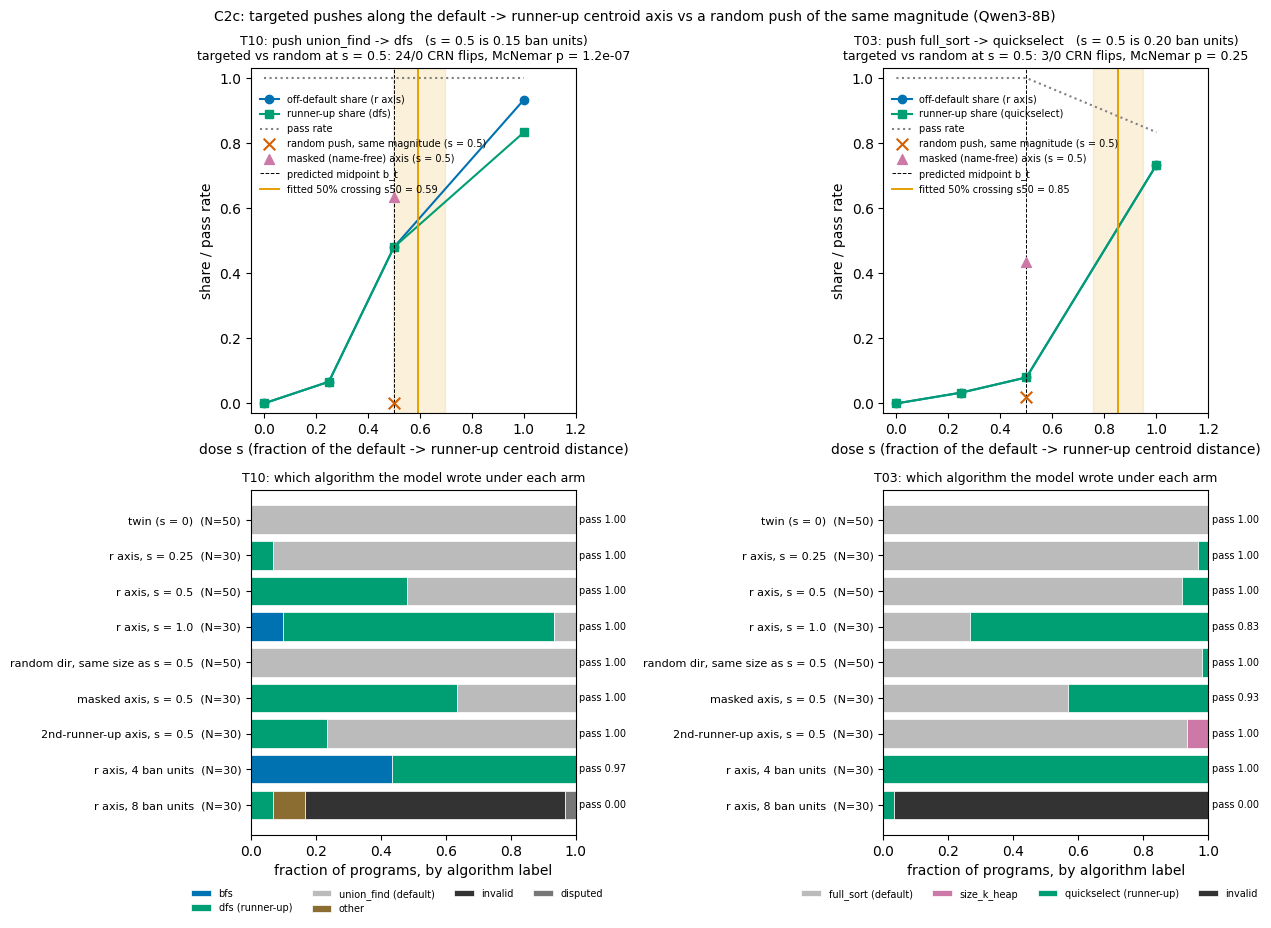

In [16]:
OI = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]   # analysis/figures.py palette

for t in TASKS:
    r = res_c2c["per_task"][t]
    a, p = r["arms"], r["targeted_vs_random"]
    rk = f"C2C_rand{SEEDS_C2C[t]}_s0.5"
    print(f"{t}: at the predicted midpoint (s = 0.5, {r['nu_0.5']:.2f} ban units) the targeted push gives "
          f"{a['C2C_r_s0.5']['runner_up_share']:.0%} {r['runner_up']} (pass {a['C2C_r_s0.5']['pass']:.0%}) vs "
          f"{a[rk]['share']:.0%} off-default for the same-magnitude random push; CRN flips "
          f"{p['flips_targeted_only']}/{p['flips_random_only']}, McNemar p = {p['mcnemar_p']:.2g}; "
          f"50% crossing s50 = {fmt_s50(r['crossing'])}")

fig, axs = plt.subplots(2, len(TASKS), figsize=(6.4 * len(TASKS), 9.4), squeeze=False)
for j, t in enumerate(TASKS):
    r = res_c2c["per_task"][t]
    a = r["arms"]
    # ---- top: dose-response along the default -> runner-up axis (layout of analysis/figures.py fig4) ----
    ax = axs[0, j]
    ss, sh, ru, hl = [], [], [], []
    for s, k in ((0.0, "TWIN"), (0.25, "C2C_r_s0.25"), (0.5, "C2C_r_s0.5"), (1.0, "C2C_r_s1.0")):
        if k in a:
            ss.append(s)
            sh.append(a[k]["share"])
            ru.append(a[k]["runner_up_share"])
            hl.append(a[k]["pass"])
    ax.plot(ss, sh, "-o", color=OI[0], label="off-default share (r axis)")
    ax.plot(ss, ru, "-s", color=OI[2], label=f"runner-up share ({r['runner_up']})")
    ax.plot(ss, hl, ":", color="grey", label="pass rate")
    rk = f"C2C_rand{SEEDS_C2C[t]}_s0.5"
    ax.scatter([0.5], [a[rk]["share"]], marker="x", s=70, color=OI[3], zorder=4,
               label="random push, same magnitude (s = 0.5)")
    if "C2C_rm_s0.5" in a:
        ax.scatter([0.5], [a["C2C_rm_s0.5"]["share"]], marker="^", s=50, color=OI[4], zorder=4,
                   label="masked (name-free) axis (s = 0.5)")
    ax.axvline(0.5, color="k", lw=0.7, ls="--", label="predicted midpoint b_t")
    cr = r["crossing"]
    if cr.get("s50") is not None and np.isfinite(cr["s50"]) and cr["s50"] <= 1.2:
        ax.axvline(cr["s50"], color=OI[1], lw=1.4, label=f"fitted 50% crossing s50 = {cr['s50']:.2f}")
        if cr.get("ci"):
            ax.axvspan(cr["ci"][0], min(cr["ci"][1], 1.2), color=OI[1], alpha=0.15)
    p = r["targeted_vs_random"]
    ax.set_title(f"{t}: push {DEFAULT4[t]} -> {r['runner_up']}   (s = 0.5 is {r['nu_0.5']:.2f} ban units)\n"
                 f"targeted vs random at s = 0.5: {p['flips_targeted_only']}/{p['flips_random_only']} CRN flips, "
                 f"McNemar p = {p['mcnemar_p']:.2g}", fontsize=9)
    ax.set_xlabel("dose s (fraction of the default -> runner-up centroid distance)")
    ax.set_ylabel("share / pass rate")
    ax.set_xlim(-0.05, 1.2)
    ax.set_ylim(-0.03, 1.03)
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(0.0, 0.95))
    # ---- bottom: which algorithm the model wrote under each arm ----
    ax = axs[1, j]
    order = [k for k in arm_order(t) if k in a]
    cat = catalogue(t)
    colours = {DEFAULT4[t]: "#BBBBBB", r["runner_up"]: OI[2], r["second"]: OI[4]}
    spare = iter([OI[0], OI[1], OI[5], OI[6], OI[3]])
    for c in cat:
        if c not in colours:
            colours[c] = next(spare)
    colours.update({"other": "#8C6D31", "invalid": "#333333", "disputed": "#777777"})
    present = [c for c in cat + ["other", "invalid", "disputed"] if any(a[k]["composition"].get(c, 0) > 0 for k in order)]
    yy = np.arange(len(order))
    left = np.zeros(len(order))
    for c in present:
        w = np.array([a[k]["composition"].get(c, 0.0) for k in order])
        ax.barh(yy, w, left=left, color=colours[c], edgecolor="white", lw=0.5,
                label=c + (" (default)" if c == DEFAULT4[t] else " (runner-up)" if c == r["runner_up"] else ""))
        left += w
    ax.set_yticks(yy, [f"{arm_name(t, k)}  (N={a[k]['n']})" for k in order], fontsize=8)
    ax.invert_yaxis()
    for i, k in enumerate(order):
        ax.text(1.01, i, f"pass {a[k]['pass']:.2f}", va="center", fontsize=7)
    ax.set_xlim(0, 1)
    ax.set_xlabel("fraction of programs, by algorithm label")
    ax.set_title(f"{t}: which algorithm the model wrote under each arm", fontsize=9)
    ax.legend(fontsize=7, frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=4)
fig.suptitle("C2c: targeted pushes along the default -> runner-up centroid axis vs a random push of the same "
             "magnitude (Qwen3-8B)", fontsize=10)
fig.tight_layout()
plt.show()

## Takeaways
- **T10: the centroid geometry is causally exact.** Push half of the default → runner-up distance: 0.15 ban units, roughly a tenth of a typical random push. About half of the programs become correct DFS. The random push of the same per-position magnitude turns none, so every discordant CRN slot favours the targeted push (24 / 0, McNemar p ≈ 1e-7). The fitted 50% crossing (≈ 0.59) sits at the predicted midpoint.
- **T03: the axis works, but only near full distance.** The crossing is at ≈ 0.85 (73% off-default at s = 1). The name-free (masked) axis is stronger than the named one at s = 0.5. At the midpoint, targeted and random cannot be told apart, so T03 counts toward DISCONFIRM. In the full run T2, T05, T06 and T1 do as well, which gives **C2c: DISCONFIRMED by the committed rule** (5/6).
- **Bigger pushes along the same axis buy alternatives, then break programs.** At 4 ban units T03 and T10 leave the default almost always and still pass. At 8 ban units almost nothing passes.
- **Read with C2a and the decomposition:** π(u) does not rank random pushes (ρ ≈ 0), and removing a push's `P_t` component leaves its escape intact. So random pushes change the algorithm through generic sensitivity, not through the plan subspace. The subspace itself is still real and reproducible, and on T10 a deliberate push along it selects the algorithm. Across 10,651 correct push programs, none was a novel algorithm: pushes recombine the catalogue rather than invent.

## Running at full scale
- **This analysis.** The config cell can use the original resampling sizes (2000 / 1000 / 1000). The full six-task C2c analysis is `python analysis/run_all.py c2c` in the experiment folder. It reads `data/samples_raw.jsonl` + `data/labels.jsonl`, which ship with the artifact, and writes `results/c2c.json`, the file compared against above.
- **The whole pipeline.** Follow `reproducibility.md` in the experiment folder: a `uv` venv from `pyproject.toml`, then `python method.py <stage>` for `s0, prompts, gpu1, commit, label, gpu2, analyze, outputs`. It needs a ≥ 16 GB CUDA GPU (about 3 GPU-hours) and an OpenRouter key; the labelling judges are cached in `data/`, so reruns are free.